# Previsione della progressione del diabete: risultati

Questo notebook riassume tutto il progetto, dall'analisi dei dati al modello esportato:

1. **Il dataset** e l'analisi esplorativa (sul solo training set).
2. **Confronto tra i modelli** di regressione in cross-validation, con attenzione all'overfitting.
3. **Selezione delle variabili** con la regressione Lasso.
4. **Valutazione finale** sul test set e intervallo di previsione.
5. **Esportazione** del modello e previsione su nuovi pazienti.

Il codice è nel pacchetto `src/diabetes`; gli script `eda.py`, `train.py` e `predict.py` eseguono gli stessi passaggi da riga di comando.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.linear_model import lasso_path
from sklearn.preprocessing import StandardScaler

from diabetes import (
    BASELINE,
    FEATURES,
    RANDOM_STATE,
    TARGET,
    build_metadata,
    build_models,
    cross_validate_models,
    interval_coverage,
    linear_coefficients,
    load_dataset,
    load_model,
    predict_with_interval,
    prediction_interval,
    regression_metrics,
    save_model,
    select_model,
    split_dataset,
)
from eda import heatmap, lineplots, scatterplots

pd.set_option("display.float_format", "{:.3f}".format)
plt.rcParams["figure.dpi"] = 90
BLUE, RED, GREY = "#1f4e79", "#c0504d", "#b0b0b0"

## 1. Il dataset

Il Diabetes dataset di scikit-learn contiene 442 pazienti e 10 variabili cliniche misurate all'inizio dello studio. Il target è una misura quantitativa della progressione della malattia un anno dopo. I dati sono caricati con i **valori originali** (`scaled=False`), più facili da interpretare per un medico.

In [2]:
X, y = load_dataset()
print(f"Pazienti: {len(X)}, variabili: {X.shape[1]}, valori mancanti: {X.isna().sum().sum()}")
pd.DataFrame({"descrizione": FEATURES, "esempio (primo paziente)": X.iloc[0]})

Pazienti: 442, variabili: 10, valori mancanti: 0


,descrizione,esempio (primo paziente)
age,età del paziente (anni),59.000
sex,"sesso (variabile binaria 0/1, vedi nota)",1.000
bmi,indice di massa corporea,32.100
bp,pressione sanguigna media,101.000
s1,colesterolo sierico totale (tc),157.000
s2,lipoproteine a bassa densità (ldl),93.200
s3,lipoproteine ad alta densità (hdl),38.000
s4,rapporto colesterolo totale / HDL (tch),4.000
s5,logaritmo dei trigliceridi sierici (ltg),4.860
s6,livello di glicemia (glu),87.000


Note sui dati:
- Non ci sono **valori mancanti**, quindi non serve imputazione.
- `sex` nel dataset originale vale 1 o 2, ma la documentazione **non indica a quale sesso corrisponda ciascun valore**. Viene quindi ricodificata come variabile binaria 0/1 senza attribuire etichette.
- Le variabili hanno scale molto diverse (per esempio `s1` intorno a 190, `s5` intorno a 4.6). Per i modelli lineari vengono standardizzate dentro la pipeline.

Prima di ogni analisi il dataset viene diviso in **training set (80%)** e **test set (20%)**. Il test set viene usato solo alla fine, per la valutazione del modello scelto.

Training set: 353 pazienti, test set: 89 pazienti


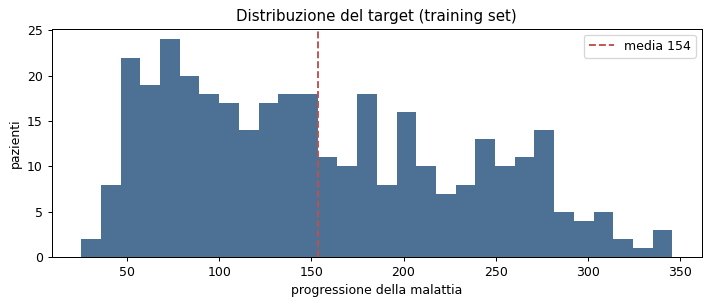

In [3]:
X_train, X_test, y_train, y_test = split_dataset(X, y)
train = X_train.assign(**{TARGET: y_train})
print(f"Training set: {len(X_train)} pazienti, test set: {len(X_test)} pazienti")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(y_train, bins=30, color=BLUE, alpha=0.8)
ax.axvline(y_train.mean(), color=RED, linestyle="--", label=f"media {y_train.mean():.0f}")
ax.set_xlabel("progressione della malattia")
ax.set_ylabel("pazienti")
ax.set_title("Distribuzione del target (training set)")
ax.legend()
plt.tight_layout()
plt.show()

### Analisi esplorativa

Relazione tra ciascuna variabile e la progressione, con la retta di tendenza e il coefficiente di correlazione *r*:

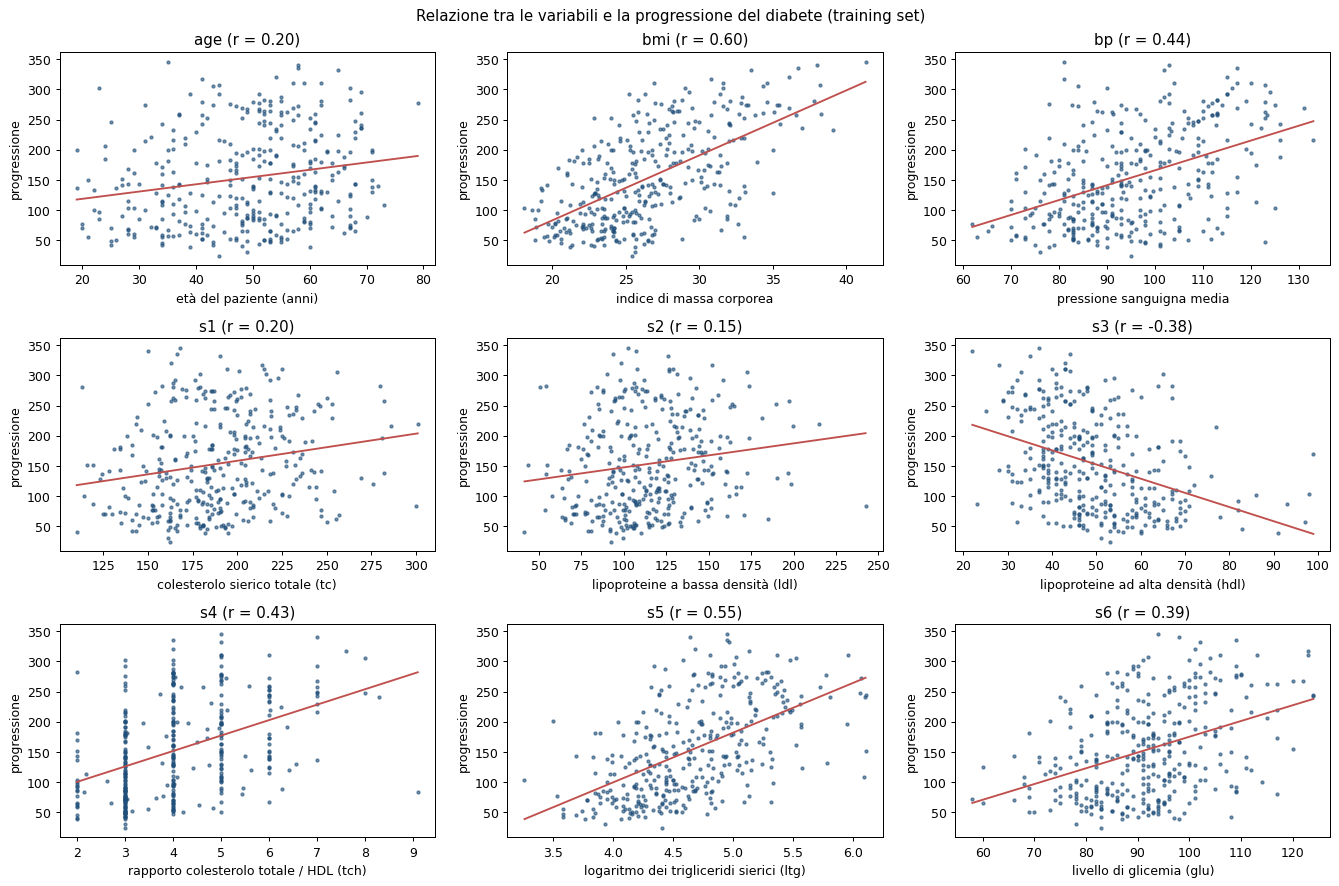

In [4]:
scatterplots(train)
plt.show()

`bmi` (r = 0.60) e `s5` (trigliceridi, r = 0.55) sono le variabili più legate alla progressione, seguite da `bp` (pressione) e `s4`. `s3` (colesterolo HDL, il "colesterolo buono") ha invece una relazione negativa.

Andamento delle principali variabili per età e sesso (le età sono raggruppate per decennio):

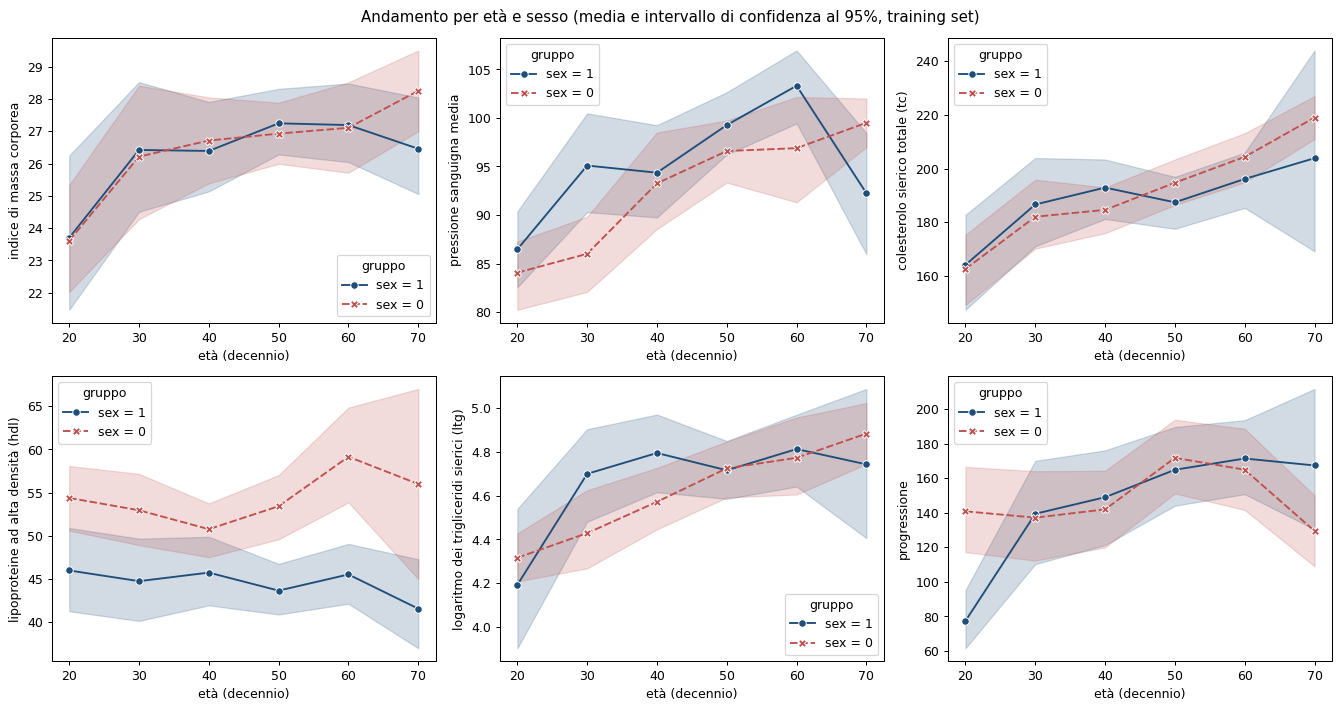

In [5]:
lineplots(train)
plt.show()

Indice di massa corporea, pressione, colesterolo e trigliceridi crescono con l'età. La differenza più netta tra i due gruppi riguarda `s3` (HDL), sistematicamente più alto nel gruppo `sex = 0`.

La matrice di correlazione evidenzia le variabili fortemente legate tra loro:

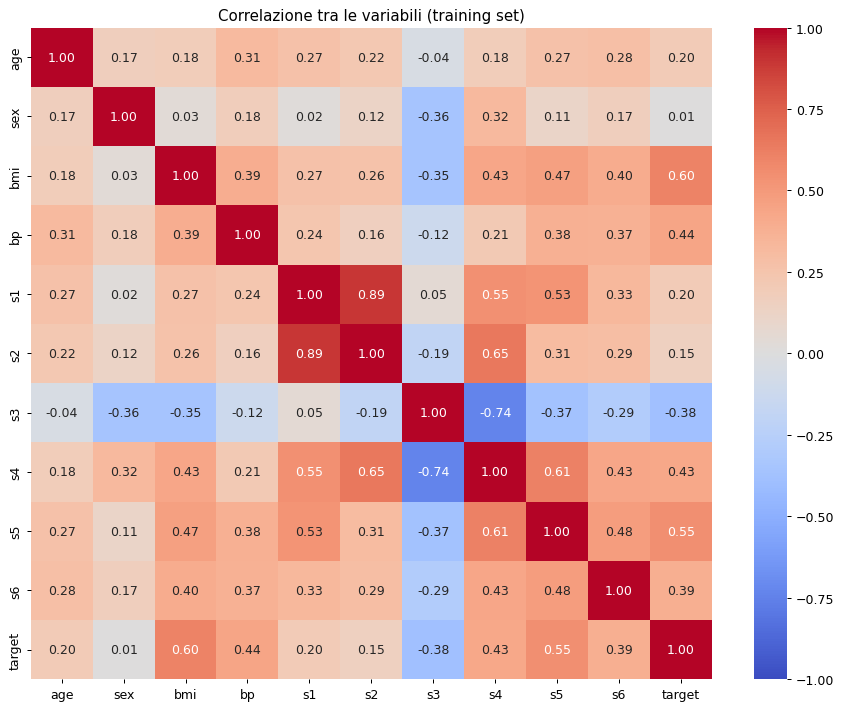

In [6]:
heatmap(train)
plt.show()

`s1` e `s2` (colesterolo totale e LDL) sono quasi la stessa informazione (correlazione 0.89), e `s3` e `s4` sono fortemente correlati in negativo. Queste ridondanze rendono instabili i coefficienti della regressione lineare e motivano l'uso della regolarizzazione (Ridge, Lasso).

## 2. Confronto tra i modelli

Tutti i modelli sono pipeline complete (standardizzazione e regressore). Vengono confrontati con una **cross-validation a 10 fold sul training set**. Oltre all'R² di validazione viene riportato quello sui dati di training di ogni fold: una grande differenza tra i due indica overfitting.

In [7]:
models = build_models(RANDOM_STATE)
results = cross_validate_models(models, X_train, y_train, random_state=RANDOM_STATE)
results

,R2,R2 std,RMSE,RMSE std,MAE,R2 training
modello,,,,,,
Baseline (media),-0.030,0.034,77.822,7.393,66.679,0.000
Regressione lineare,0.478,0.057,55.182,4.716,45.083,0.529
Ridge,0.476,0.056,55.299,4.744,45.204,0.528
Lasso,0.477,0.057,55.248,4.762,45.173,0.523
ElasticNet,0.476,0.053,55.351,4.893,45.268,0.523
Polinomiale grado 2,0.358,0.108,61.085,6.355,48.884,0.615
Polinomiale grado 3,-130.843,188.809,714.109,501.873,335.361,0.923
Polinomiale grado 2 + Ridge,0.442,0.065,57.027,4.339,46.637,0.562
Random forest,0.435,0.110,57.227,6.606,47.074,0.762


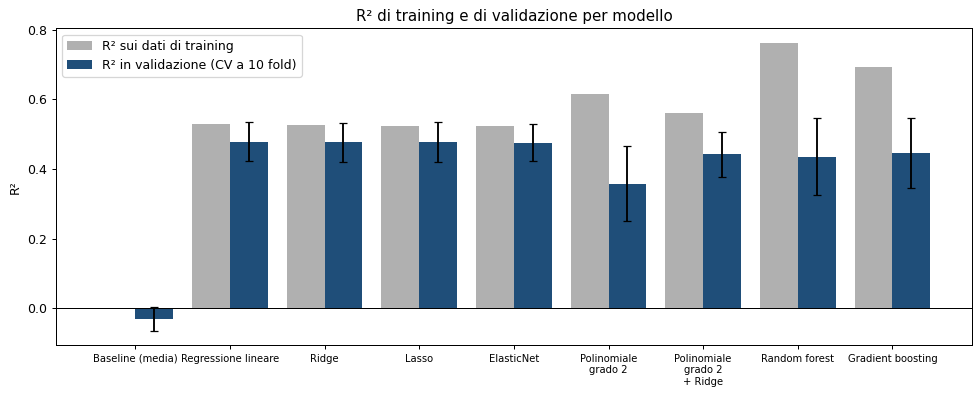

Polinomiale grado 3 (escluso dal grafico): R² training 0.92, R² validazione -130.8


In [8]:
shown = results.drop(index="Polinomiale grado 3")
fig, ax = plt.subplots(figsize=(11, 4.5))
positions = np.arange(len(shown))
ax.bar(positions - 0.2, shown["R2 training"], 0.4, color=GREY, label="R² sui dati di training")
ax.bar(positions + 0.2, shown["R2"], 0.4, yerr=shown["R2 std"], capsize=3, color=BLUE,
       label="R² in validazione (CV a 10 fold)")
ax.set_xticks(positions)
ax.set_xticklabels([name.replace(" + ", "\n+ ").replace(" grado", "\ngrado") for name in shown.index], fontsize=8)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("R²")
ax.set_title("R² di training e di validazione per modello")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()
print(f"Polinomiale grado 3 (escluso dal grafico): R² training {results.loc['Polinomiale grado 3', 'R2 training']:.2f}, "
      f"R² validazione {results.loc['Polinomiale grado 3', 'R2']:.1f}")

Osservazioni:
- La **baseline** (predice sempre la media) ha R² circa 0. Tutti i modelli sensati la superano nettamente.
- **Regressione lineare, Ridge, Lasso ed ElasticNet** sono equivalenti (R² di circa 0.48), con un R² di training poco più alto: nessun overfitting.
- I **polinomiali senza regolarizzazione** vanno in overfitting. Il grado 2 peggiora in validazione pur migliorando sul training. Il grado 3 arriva a R² 0.92 sul training ma è disastroso su dati nuovi: con 285 variabili per circa 320 pazienti per fold il modello impara il rumore. È esattamente l'errore che si commette valutando i modelli sui dati usati per addestrarli.
- **Random forest e gradient boosting** non migliorano i modelli lineari: con 442 pazienti la relazione è descritta bene da un modello lineare.

Per la scelta si usa la **regola di una deviazione standard**: tra i modelli con RMSE entro una deviazione standard dal migliore, si sceglie il più semplice.

In [9]:
best, chosen = select_model(results)
print(f"Modello con RMSE più basso: {best}")
print(f"Modello scelto: {chosen}")

Modello con RMSE più basso: Regressione lineare
Modello scelto: Regressione lineare


## 3. Selezione delle variabili con il Lasso

Il Lasso penalizza la somma dei valori assoluti dei coefficienti e ne porta alcuni esattamente a zero, eliminando le variabili meno utili. L'intensità della penalità (`alpha`) è scelta in cross-validation. Il grafico a sinistra mostra come i coefficienti si azzerano all'aumentare di `alpha`; a destra i coefficienti con l'`alpha` scelto.

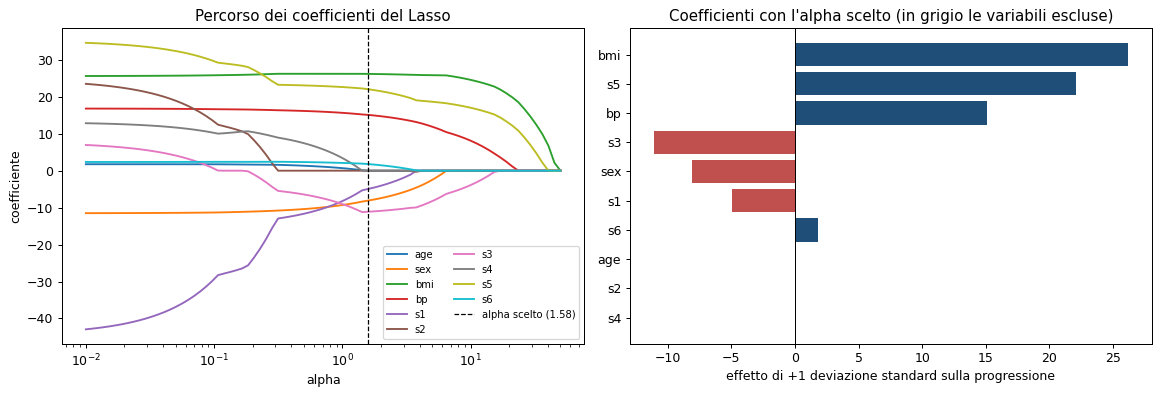

Variabili escluse: ['age', 's2', 's4']


In [10]:
lasso = clone(models["Lasso"]).fit(X_train, y_train)
alpha = lasso.named_steps["model"].alpha_
coefficients = linear_coefficients(lasso, X_train.columns)

alphas, path, _ = lasso_path(StandardScaler().fit_transform(X_train), y_train - y_train.mean(),
                             alphas=np.logspace(-2, 1.7, 80))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, coef in zip(X_train.columns, path):
    axes[0].plot(alphas, coef, label=name)
axes[0].axvline(alpha, color="black", linestyle="--", linewidth=1, label=f"alpha scelto ({alpha:.2f})")
axes[0].set_xscale("log")
axes[0].set_xlabel("alpha")
axes[0].set_ylabel("coefficiente")
axes[0].set_title("Percorso dei coefficienti del Lasso")
axes[0].legend(fontsize=8, ncol=2)

ordered = coefficients.iloc[::-1]
axes[1].barh(ordered.index, ordered, color=[GREY if c == 0 else (BLUE if c > 0 else RED) for c in ordered])
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_xlabel("effetto di +1 deviazione standard sulla progressione")
axes[1].set_title("Coefficienti con l'alpha scelto (in grigio le variabili escluse)")
plt.tight_layout()
plt.show()
print(f"Variabili escluse: {list(coefficients[coefficients == 0].index)}")

Il Lasso conserva le variabili più importanti, `bmi`, `s5` e `bp` (effetto positivo) e `s3` (effetto negativo), ed esclude `age`, `s2` e `s4`. L'informazione di queste ultime è già contenuta nelle variabili correlate (`s2` in `s1`, `s4` in `s3`).

`sex` viene invece mantenuta, pur avendo correlazione quasi nulla con il target (0.01). A parità delle altre variabili ha un effetto negativo: il suo contributo emerge solo considerandola insieme alle altre. Per questo il repository originale, che escludeva `sex` a mano, otteneva un modello leggermente peggiore.

Le prestazioni sono equivalenti a quelle della regressione lineare con tutte le variabili. Il Lasso è utile soprattutto per **capire** quali variabili contano e per un modello più semplice da spiegare.

## 4. Valutazione finale sul test set

In [11]:
model = clone(models[chosen]).fit(X_train, y_train)
y_pred = model.predict(X_test)
baseline = clone(models[BASELINE]).fit(X_train, y_train)
test_metrics = regression_metrics(y_test, y_pred)
pd.DataFrame({chosen: test_metrics, BASELINE: regression_metrics(y_test, baseline.predict(X_test))}).T

,R2,RMSE,MAE
Regressione lineare,0.453,53.853,42.794
Baseline (media),-0.012,73.222,64.006


Sul test set, mai usato prima, il modello ottiene un R² di circa 0.45 e un errore medio (RMSE) di circa 54 punti, contro i 73 della baseline. I valori sono coerenti con la cross-validation: la stima delle prestazioni è affidabile.

### Intervallo di previsione
Per un uso clinico non basta la previsione puntuale: serve sapere quanto ci si può sbagliare. L'intervallo al 90% è stimato dai residui in cross-validation sul training set, e la sua copertura viene verificata sul test set.

Intervallo al 90%: previsione da -88.9 a +92.0
Pazienti del test set dentro l'intervallo: 93.3%


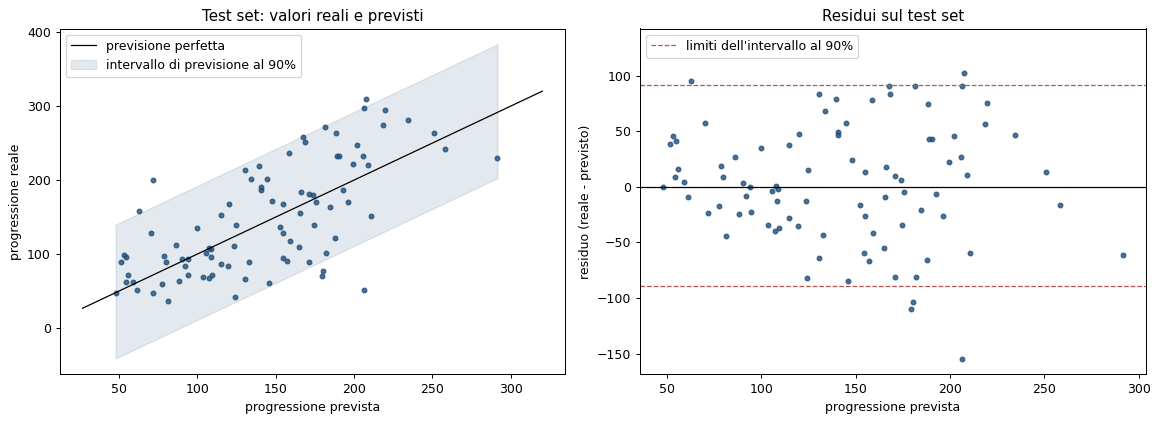

In [12]:
interval = prediction_interval(models[chosen], X_train, y_train, level=0.9, random_state=RANDOM_STATE)
coverage = interval_coverage(y_test, y_pred, interval)
print(f"Intervallo al 90%: previsione da {interval['inferiore']:+.1f} a {interval['superiore']:+.1f}")
print(f"Pazienti del test set dentro l'intervallo: {coverage:.1%}")

order = np.argsort(y_pred)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].scatter(y_pred, y_test, s=14, color=BLUE, alpha=0.8)
limits = [min(y_test.min(), y_pred.min()) - 10, max(y_test.max(), y_pred.max()) + 10]
axes[0].plot(limits, limits, color="black", linewidth=1, label="previsione perfetta")
axes[0].fill_between(np.sort(y_pred), np.sort(y_pred) + interval["inferiore"], np.sort(y_pred) + interval["superiore"],
                     color=BLUE, alpha=0.12, label="intervallo di previsione al 90%")
axes[0].set_xlabel("progressione prevista")
axes[0].set_ylabel("progressione reale")
axes[0].set_title("Test set: valori reali e previsti")
axes[0].legend(loc="upper left")

residuals = y_test - y_pred
axes[1].scatter(y_pred, residuals, s=14, color=BLUE, alpha=0.8)
axes[1].axhline(0, color="black", linewidth=1)
axes[1].axhline(interval["inferiore"], color=RED, linestyle="--", linewidth=1)
axes[1].axhline(interval["superiore"], color=RED, linestyle="--", linewidth=1, label="limiti dell'intervallo al 90%")
axes[1].set_xlabel("progressione prevista")
axes[1].set_ylabel("residuo (reale - previsto)")
axes[1].set_title("Residui sul test set")
axes[1].legend(loc="upper left")
plt.tight_layout()
plt.show()

L'intervallo è **ampio** (circa ±90 punti su un target che va da 25 a 346). Le 10 variabili cliniche spiegano poco meno della metà della variabilità della progressione: il modello indica in modo affidabile se un paziente è a rischio basso, medio o alto, ma non prevede il valore esatto. Questo limite va comunicato chiaramente ai medici che useranno lo strumento.

## 5. Esportazione e previsione su nuovi pazienti

Il modello finale viene riaddestrato su tutti i 442 pazienti ed esportato con `joblib`. Il file contiene la **pipeline completa**, standardizzazione compresa, quindi accetta direttamente i valori clinici originali. Accanto al modello viene salvato un file di metadati: variabili attese, intervalli dei valori visti in addestramento, metriche, intervallo di previsione e versioni delle librerie.

In [13]:
final_model = clone(models[chosen]).fit(X, y)
metadata = build_metadata(chosen, X, test_metrics, {**interval, "copertura_test": coverage},
                          cv_results=results.loc[chosen].to_dict())
path = save_model(final_model, metadata, ROOT / "models")
print(f"Modello esportato in {path.relative_to(ROOT).as_posix()}")

loaded, metadata = load_model(ROOT / "models")
new_patients = pd.DataFrame([
    {"age": 45, "sex": 0, "bmi": 22.0, "bp": 80, "s1": 170, "s2": 95, "s3": 60, "s4": 3.0, "s5": 4.3, "s6": 85},
    {"age": 60, "sex": 1, "bmi": 32.5, "bp": 110, "s1": 210, "s2": 130, "s3": 38, "s4": 5.5, "s5": 5.3, "s6": 105},
    {"age": 30, "sex": 0, "bmi": 45.0, "bp": 95, "s1": 190, "s2": 115, "s3": 45, "s4": 4.0, "s5": 4.8, "s6": 95},
], index=["paziente A", "paziente B", "paziente C"])
predict_with_interval(loaded, metadata, new_patients)

Modello esportato in models/diabetes_model.joblib


,previsione,minimo,massimo,fuori_intervallo_training
paziente A,99.369,10.466,191.366,
paziente B,233.061,144.158,325.058,
paziente C,276.661,187.757,368.657,bmi


Il paziente A (peso normale, pressione e trigliceridi bassi, HDL alto) ha una progressione prevista bassa, il paziente B (obesità, ipertensione, HDL basso) alta. Per il paziente C il BMI di 45 è fuori dai valori visti in addestramento (massimo 42.2): la previsione viene comunque calcolata ma segnalata come meno affidabile.

## Conclusioni

- Il modello scelto è una **regressione lineare** con standardizzazione: semplice, interpretabile e non peggiore di Ridge, Lasso, ElasticNet o dei modelli ad alberi.
- Le prestazioni (R² circa 0.45–0.48, RMSE circa 54) sono stimate in modo affidabile, in cross-validation e su un test set indipendente, e sono nettamente migliori della baseline.
- Le variabili più influenti sono **BMI, trigliceridi (s5), pressione (bp) e colesterolo HDL (s3)**.
- I modelli più complessi (polinomiali) sembrano migliori solo se valutati sui dati di addestramento: in realtà vanno in overfitting.
- L'incertezza delle previsioni è elevata (intervallo al 90% di circa ±90 punti): il modello va usato come **supporto** alla valutazione clinica, non come sostituto.